In [18]:
!pip install -U albumentations

# Imports 📦

In [19]:
import os
import glob
import tensorflow as tf
import tensorflow.keras.backend as K
import albumentations as A
from albumentations.core.composition import OneOf

import numpy as np
import random
import matplotlib.pyplot as plt
import cv2

In [20]:
import tensorflow as tf
print(tf.__version__)

2.17.1


# Data 📊

In [21]:
image_dir = '/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images'
mask_dir = '/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images'

image_paths = sorted(glob.glob(os.path.join(image_dir, '*.png')))
mask_paths = sorted(glob.glob(os.path.join(mask_dir, '*.png')))

In [22]:
print("Sample ultrasound images:", image_paths[0:2])
print("-"*100)
print("Sample masks:", mask_paths[:2])
print("="*100)
print(f"Total images: {len(image_paths)}")  
print(f"Total masks: {len(mask_paths)}")   

Sample ultrasound images: ['/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images/202201121748100022VAS_slice_1069.png', '/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images/202201121748100022VAS_slice_1080.png']
----------------------------------------------------------------------------------------------------
Sample masks: ['/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201121748100022VAS_slice_1069.png', '/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201121748100022VAS_slice_1080.png']
Total images: 1100
Total masks: 1100


In [23]:
if len(image_paths) == 0 or len(mask_paths) == 0:
    print("Error: No image or mask paths found. Check paths and extensions.")
elif len(image_paths) != len(mask_paths):
    print(f"Error: The number of images ({len(image_paths)}) and masks ({len(mask_paths)}) do not match.")
else:
    print(f"{len(image_paths)} matched image/mask pairs found.")
    BUFFER_SIZE = len(image_paths)


1100 matched image/mask pairs found.


In [24]:
transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.95, 1.05), translate_percent=(0.05, 0.05), rotate=(-15, 15), p=0.5), 
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3), 
    A.ElasticTransform(alpha=1, sigma=50, p=0.3), 
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),
    A.GaussNoise((0.001, 0.005), p=0.3),
    A.GaussianBlur(blur_limit=(3, 7), p=0.3),
    A.GridDistortion(p=0.2),
    A.VerticalFlip(p=0.5), 
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.2), 
    A.RandomCrop(height=256, width=256, p=0.3),  
    A.MotionBlur(blur_limit=7, p=0.2),          
    A.Sharpen(alpha=(0.2, 0.5), lightness=(0.5, 1.0), p=0.2),  
])

In [25]:
image_transform = A.Compose([
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),
    A.GaussNoise((0.001, 0.005), p=0.3),
    A.GaussianBlur(blur_limit=(3, 7), p=0.3),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.2),
    A.MotionBlur(blur_limit=7, p=0.2),
    A.Sharpen(alpha=(0.2, 0.5), lightness=(0.5, 1.0), p=0.2),
])


shared_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
    A.ElasticTransform(alpha=1, sigma=50, p=0.3),
    A.GridDistortion(p=0.2),
    A.VerticalFlip(p=0.5),
    A.RandomCrop(height=256, width=256, p=0.3),
])

In [26]:
def load_data(image_path, mask_path):
    if isinstance(image_path, tf.Tensor):
        image_path = image_path.numpy()
    if isinstance(mask_path, tf.Tensor):
        mask_path = mask_path.numpy()
    
    if isinstance(image_path, bytes):
        image_path = image_path.decode('utf-8')
    if isinstance(mask_path, bytes):
        mask_path = mask_path.decode('utf-8')
    
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Failed to load image at {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Failed to load mask at {mask_path}")
    
    image = image.astype(np.float32) / 255.0
    mask = mask.astype(np.float32) / 255.0
    return image, mask

def preprocess(image_path, mask_path):
    image, mask = load_data(image_path, mask_path)
    
    # Resize to match model input
    image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)
    
    augmented = transform(image=image, mask=mask)
    image, mask = augmented["image"], augmented["mask"]
    
    return image, mask[..., np.newaxis]

'''
def preprocess(image_path, mask_path):
    image, mask = load_data(image_path, mask_path)
    image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)
    # Önce görüntüye özel dönüşüm
    image_aug = image_transform(image=image)["image"]
    # Sonra ortak dönüşüm
    augmented = shared_transform(image=image_aug, mask=mask)
    return augmented["image"], augmented["mask"][..., np.newaxis]'''

def tf_preprocess(image_path, mask_path):
    image, mask = tf.numpy_function(
        preprocess, 
        [image_path, mask_path], 
        [tf.float32, tf.float32]
    )
    image.set_shape([256, 256, 3])
    mask.set_shape([256, 256, 1])
    return image, mask

In [27]:
# Build dataset
dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
dataset = dataset.shuffle(len(image_paths))
dataset = dataset.map(tf_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.prefetch(tf.data.AUTOTUNE)  # Prefetch without batching here

In [28]:
# Calculate sizes
total_samples = len(image_paths)
train_size = int(0.8 * total_samples)
val_size = total_samples - train_size
print(f"Total samples: {total_samples}")
print(f"Train size: {train_size}")
print(f"Validation size: {val_size}")
print(f"Validation steps: {max(1, (len(image_paths) - train_size) // 4)}")

Total samples: 1100
Train size: 880
Validation size: 220
Validation steps: 55


In [29]:
# Train ve Validation datasetlerini ayır
train_size = int(0.8 * len(image_paths))
train_dataset = dataset.take(train_size).batch(8).repeat().prefetch(tf.data.AUTOTUNE)
val_dataset = dataset.skip(train_size).batch(4).repeat().prefetch(tf.data.AUTOTUNE)

# Calculate steps
train_steps = train_size // 8
val_steps = max(1, (len(image_paths) - train_size) // 4)

print(f"Train steps: {train_steps}")
print(f"Validation steps: {val_steps}")

Train steps: 110
Validation steps: 55


In [30]:
for image_batch, mask_batch in train_dataset.take(1):
    print("Image batch shape:", image_batch.shape)
    print("Mask batch shape:", mask_batch.shape)

Image batch shape: (8, 256, 256, 3)
Mask batch shape: (8, 256, 256, 1)


In [31]:
for image_batch, mask_batch in val_dataset.take(1):
    print("Validation batch - Image shape:", image_batch.shape)
    print("Validation batch - Mask shape:", mask_batch.shape)

Validation batch - Image shape: (4, 256, 256, 3)
Validation batch - Mask shape: (4, 256, 256, 1)


In [32]:
image_path = image_paths[0]
mask_path = mask_paths[0]

print("Type of image_path:", type(image_path))
print("Type of mask_path:", type(mask_path))

image, mask = load_data(image_path, mask_path)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

Type of image_path: <class 'str'>
Type of mask_path: <class 'str'>
Image shape: (749, 709, 3)
Mask shape: (749, 709)


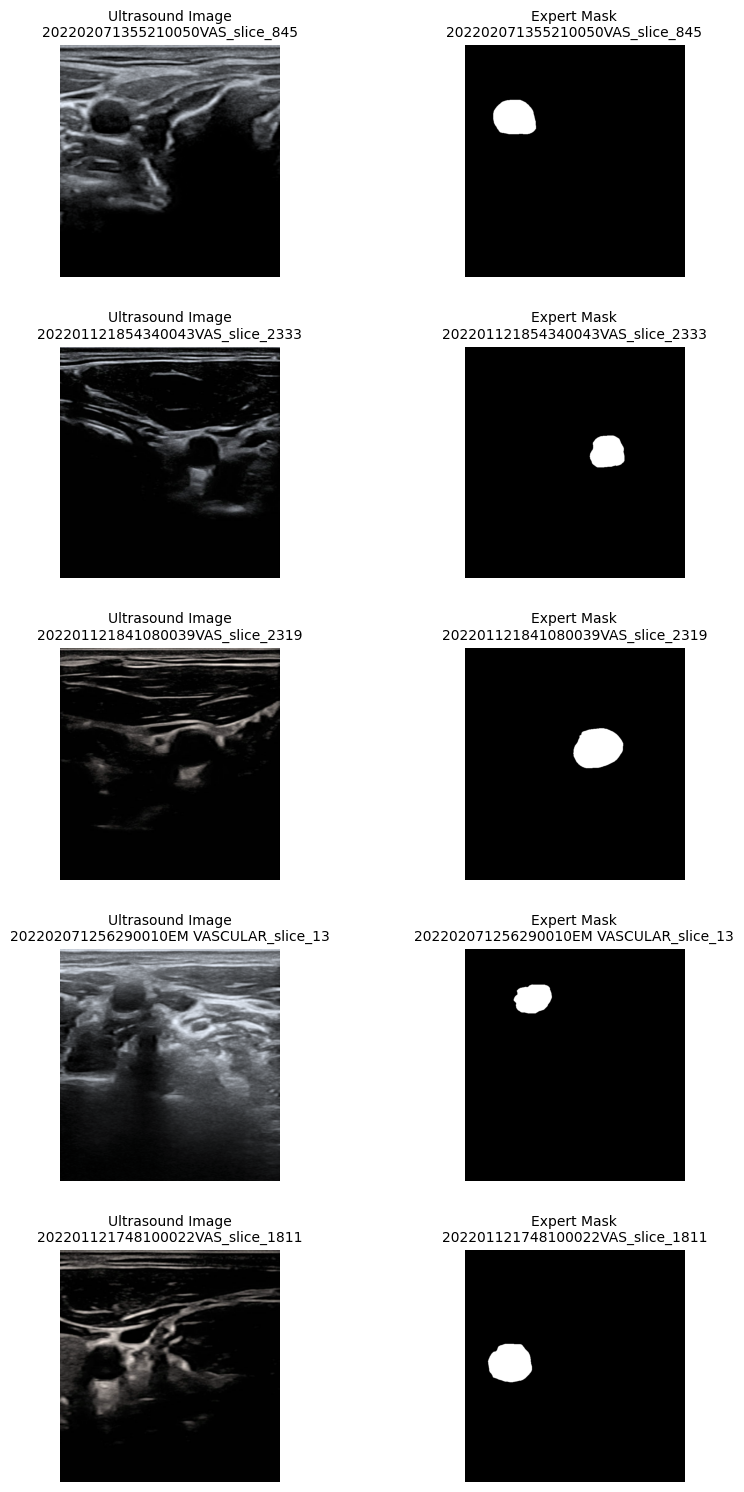

In [33]:
import matplotlib.pyplot as plt
import cv2
import os
import random

fig, axes = plt.subplots(5, 2, figsize=(8, 15))  # Smaller figure size

for idx in range(5):
    random_index = random.randint(0, len(image_paths) - 1)

    img_path = os.path.join(image_dir, image_paths[random_index])
    mask_path = os.path.join(mask_dir, mask_paths[random_index])

    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(
        f"Ultrasound Image\n{os.path.splitext(os.path.basename(image_paths[random_index]))[0]}", fontsize=10
    )
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(mask, cmap='gray')
    axes[idx, 1].set_title(
        f"Expert Mask\n{os.path.splitext(os.path.basename(mask_paths[random_index]))[0]}", fontsize=10
    )
    axes[idx, 1].axis('off')

plt.tight_layout(pad=1.0)
plt.subplots_adjust(hspace=0.3, wspace=0.1)  # Tighter spacing
plt.show()


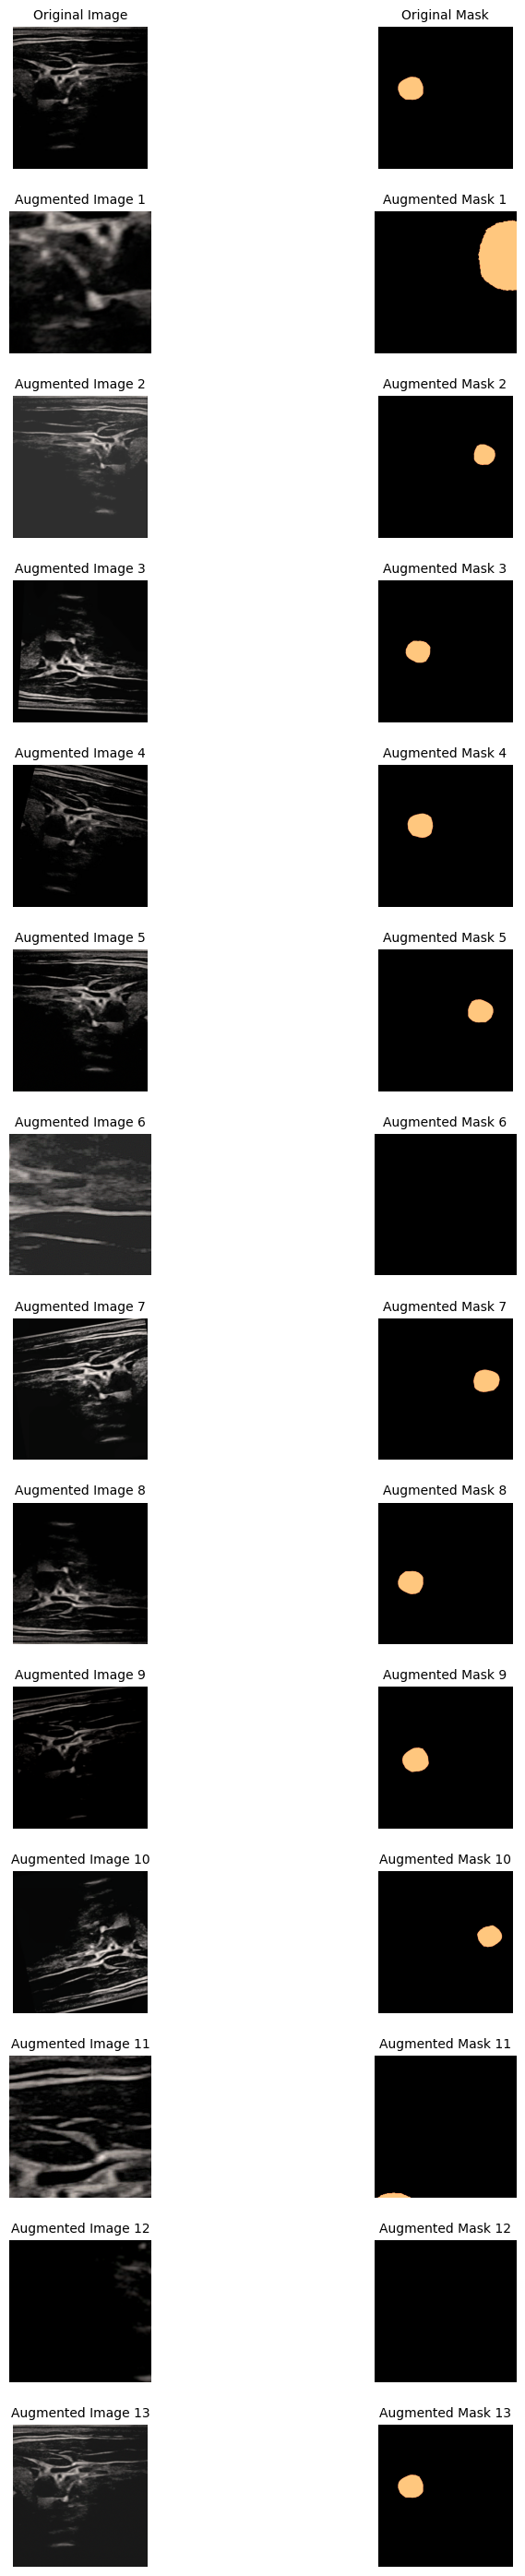

In [34]:
def load_image_and_mask(image_path, mask_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image, channels=3).numpy()
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_image(mask, channels=1).numpy()
    return image, mask

def visualize_augmentation(image_path, mask_path, transform, num_samples=5):
    original_image, original_mask = load_image_and_mask(image_path, mask_path)
    
    plt.figure(figsize=(8, num_samples * 2))  # Smaller figure size

    # Show original image and mask
    plt.subplot(num_samples, 2, 1)
    plt.title("Original Image", fontsize=10)
    plt.imshow(original_image)
    plt.axis('off')

    plt.subplot(num_samples, 2, 2)
    plt.title("Original Mask", fontsize=10)
    plt.imshow(original_mask.squeeze(), cmap='copper')
    plt.axis('off')
    
    # Show augmented samples
    for i in range(num_samples - 1):
        augmented = transform(image=original_image, mask=original_mask)
        aug_image = augmented['image']
        aug_mask = augmented['mask']

        plt.subplot(num_samples, 2, (i + 1) * 2 + 1)
        plt.title(f"Augmented Image {i+1}", fontsize=10)
        plt.imshow(aug_image)
        plt.axis('off')

        plt.subplot(num_samples, 2, (i + 1) * 2 + 2)
        plt.title(f"Augmented Mask {i+1}", fontsize=10)
        plt.imshow(aug_mask.squeeze(), cmap='copper')
        plt.axis('off')

    plt.tight_layout(pad=1.0)  # Reduce padding
    plt.subplots_adjust(hspace=0.3, wspace=0.05)  # Less vertical and horizontal spacing
    plt.show()

image_path = "/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images/202201121748100022VAS_slice_1069.png"
mask_path = "/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201121748100022VAS_slice_1069.png"  # Maske dosya yolunu ekle
visualize_augmentation(image_path, mask_path, transform, num_samples=14)

In [35]:
def visualize_sample(image_path, mask_path):
    image, mask = load_data(image_path, mask_path)

    # Apply augmentation
    augmented = transform(image=image, mask=mask)
    aug_image, aug_mask = augmented["image"], augmented["mask"]

    fig, ax = plt.subplots(1, 4, figsize=(12, 5))

    # Original image and mask
    ax[0].imshow(image)
    ax[0].set_title("Original Image")
    ax[0].axis("off")

    ax[1].imshow(mask, cmap="gray")
    ax[1].set_title("Original Mask")
    ax[1].axis("off")

    # Augmented image and mask
    ax[2].imshow(aug_image)
    ax[2].set_title("Augmented Image")
    ax[2].axis("off")

    ax[3].imshow(aug_mask, cmap="gray")
    ax[3].set_title("Augmented Mask")
    ax[3].axis("off")

    plt.show()


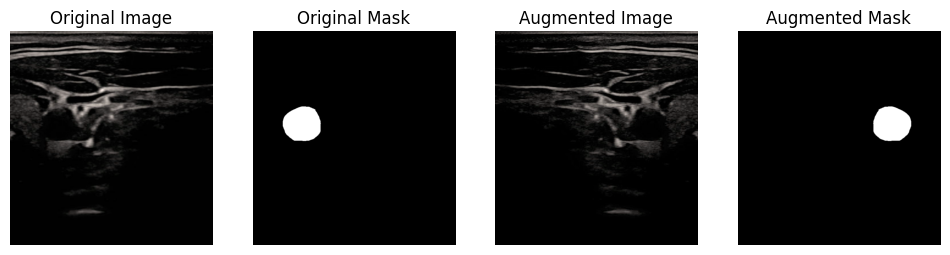

In [39]:
visualize_sample(image_paths[0], mask_paths[0])

#### visualize_sample(image_paths[0], mask_paths[0])

In [40]:
def load_image(image_path):
    """ Görseli yükleyip NumPy array formatına çevirir. """
    image = cv2.imread(image_path)  
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  
    return image

def load_mask(mask_path):
    """ Maskeyi grayscale formatında yükler. """
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    return mask

def show_random_masks(image_paths, mask_paths, num_samples=15, color_map="jet"):
    """ Rastgele resim ve maskeleri üst üste gösterir. """
    plt.figure(figsize=(13, 8))

    for i in range(num_samples):
        plt.subplot(3, 5, i + 1)
        idx = np.random.randint(len(image_paths))  # Rastgele bir indeks seç
        image = load_image(image_paths[idx])
        mask = load_mask(mask_paths[idx])

        plt.imshow(image)  # Orijinal resim
        plt.imshow(mask, cmap=color_map, alpha=0.5)  # Şeffaf maskeyi üstüne ekle
        plt.axis('off')

    plt.tight_layout()
    plt.show()

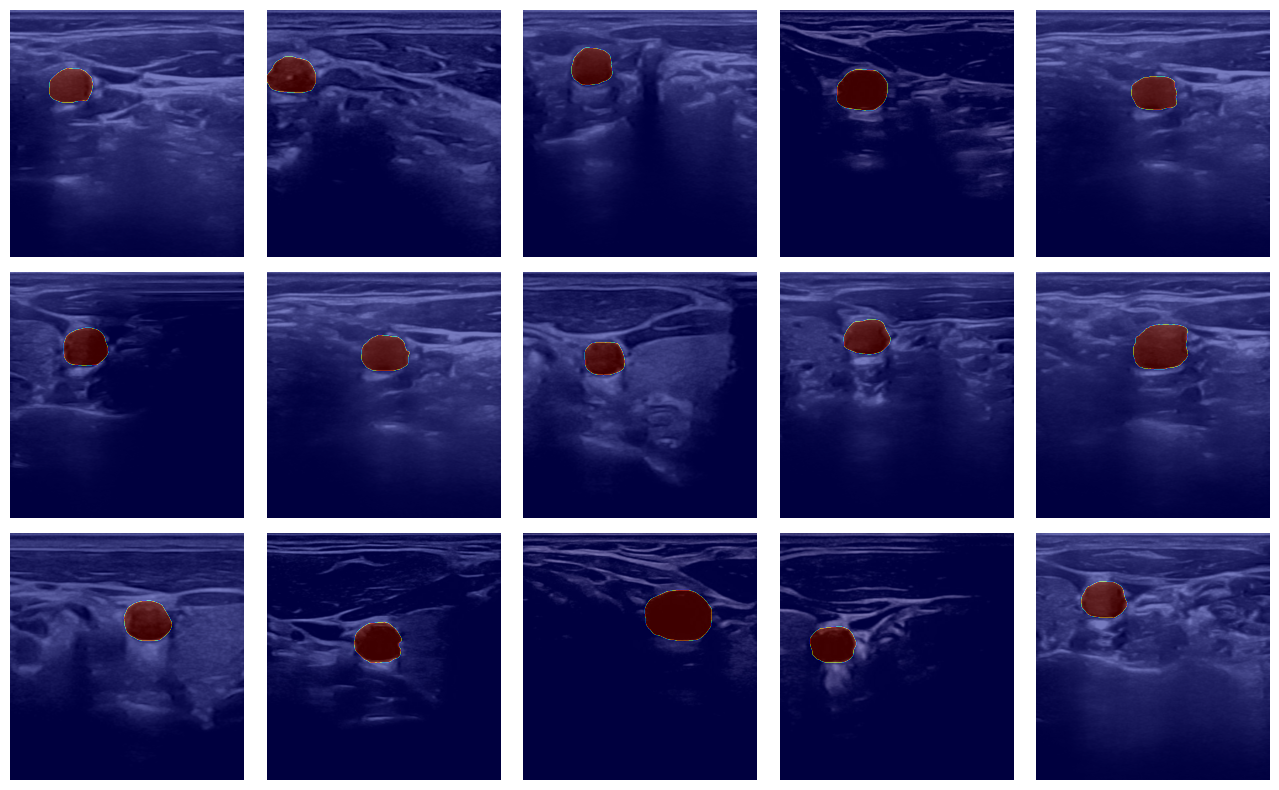

In [26]:
show_random_masks(image_paths, mask_paths, num_samples=15, color_map='jet')

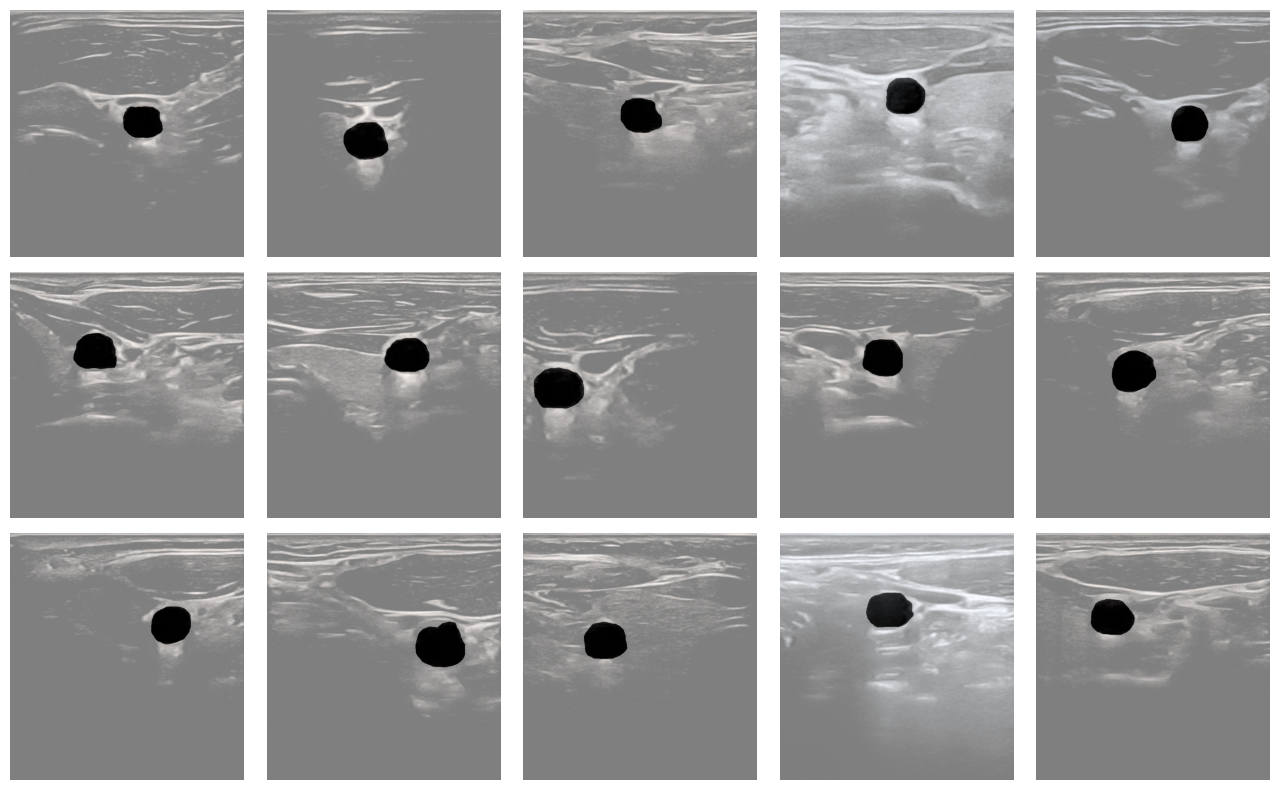

In [27]:
show_random_masks(image_paths, mask_paths, num_samples=15, color_map='binary')

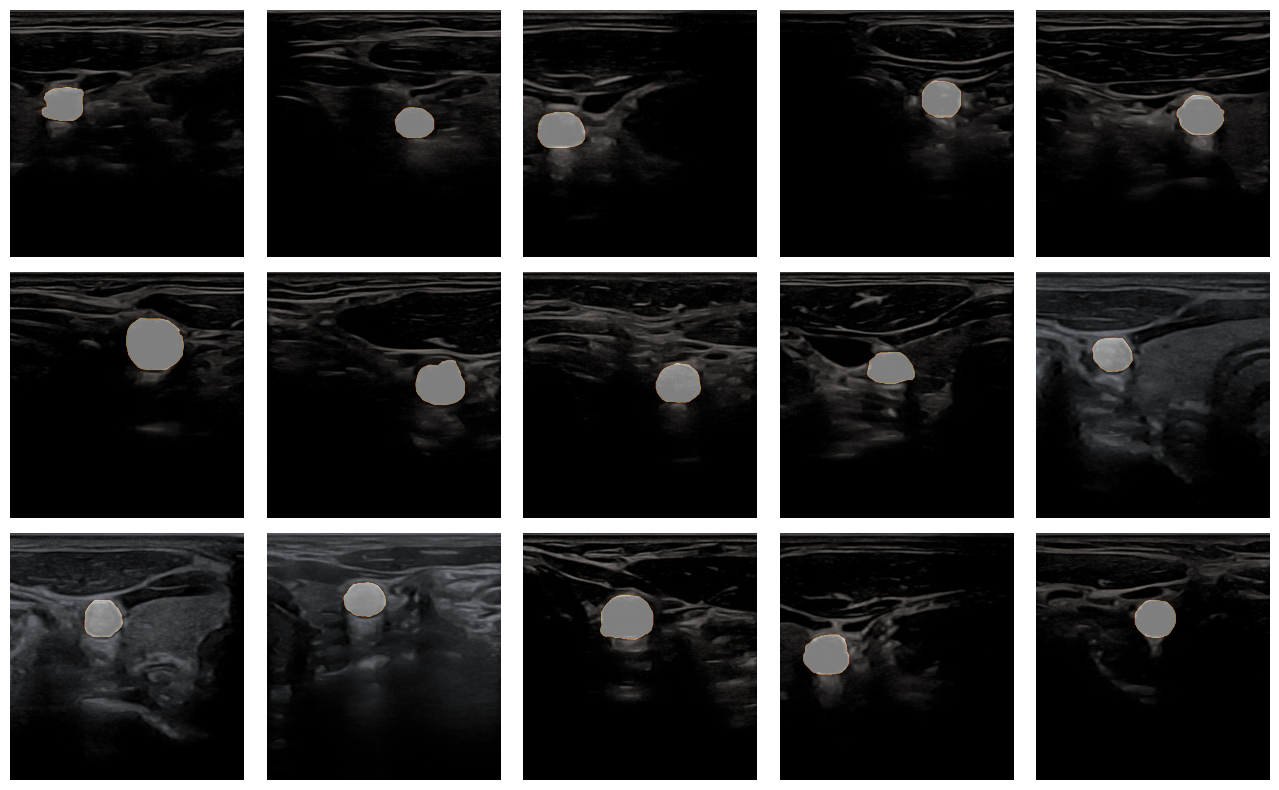

In [28]:
show_random_masks(image_paths, mask_paths, num_samples=15, color_map='afmhot')

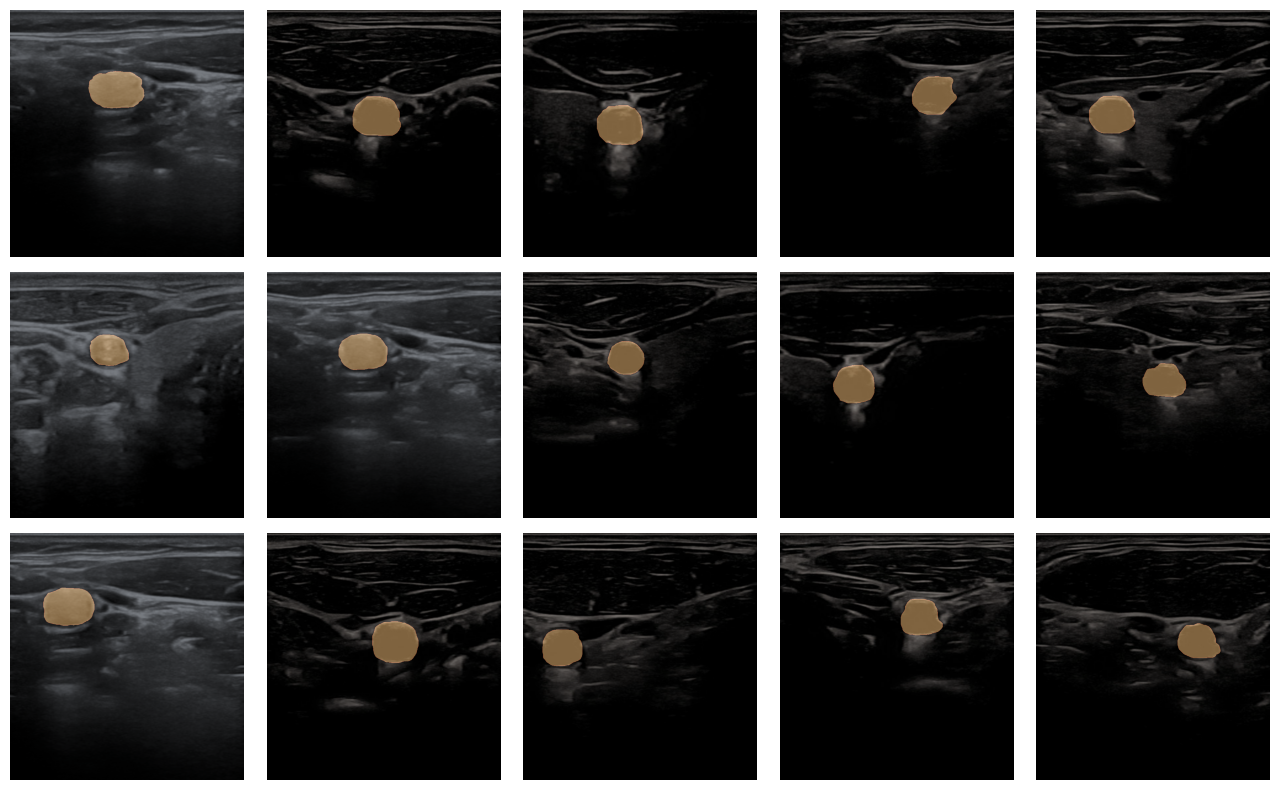

In [29]:
show_random_masks(image_paths, mask_paths, num_samples=15, color_map='copper')

# Model (Attention U-NET) 🧠

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPool2D, UpSampling2D, Dropout, Add, Multiply
from tensorflow.keras.layers import BatchNormalization, concatenate, Input, Layer, Activation

from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, Callback

In [ ]:
# Encoder Block
class EncoderBlock(tf.keras.layers.Layer):
    def __init__(self, filters, dropout_rate=0.1, pooling=True, **kwargs):
        super().__init__(**kwargs)
        self.conv1 = Conv2D(filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')
        self.drop = Dropout(dropout_rate)
        self.conv2 = Conv2D(filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')
        self.pool = MaxPool2D() if pooling else None
        
    def call(self, x, training=False):
        x = self.conv1(x)
        x = self.drop(x, training=training)
        x = self.conv2(x)
        return (self.pool(x), x) if self.pool else x

In [ ]:
# Decoder Block
class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, filters, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.up = UpSampling2D()
        self.encoder = EncoderBlock(filters, dropout_rate, pooling=False)
        
    def call(self, inputs, training=False):
        x, skip_x = inputs
        x = self.up(x)
        
        # Handle different shapes by resizing
        if x.shape[1] != skip_x.shape[1] or x.shape[2] != skip_x.shape[2]:
            x = tf.image.resize(x, (skip_x.shape[1], skip_x.shape[2]))
            
        x = concatenate([x, skip_x], axis=3)
        return self.encoder(x, training=training)

In [ ]:
class AttentionGate(Layer):
    def __init__(self, filters, batchnorm=True, **kwargs):
        super(AttentionGate, self).__init__(**kwargs)
        self.filters = filters
        self.batchnorm = batchnorm
        self.W_g = Conv2D(filters, (1, 1), padding='same', kernel_initializer='he_normal')
        self.W_x = Conv2D(filters, (1, 1), padding='same', kernel_initializer='he_normal')
        self.psi = Conv2D(1, (1, 1), padding='same', activation='sigmoid', kernel_initializer='he_normal')
        self.batchnorm_layer = BatchNormalization()
    
    def call(self, inputs, training=None):
        g, x = inputs  # g: input from lower layer, x: skip connection
        
        # Process inputs
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        
        # Dynamic resizing for shape compatibility
        if g1.shape[1] != x1.shape[1] or g1.shape[2] != x1.shape[2]:
            g1 = tf.image.resize(g1, (x1.shape[1], x1.shape[2]))
        
        # Attention mechanism
        psi = Activation('relu')(Add()([g1, x1]))
        psi = self.psi(psi)
        
        # Apply attention weights
        out = Multiply()([x, psi])
        
        if self.batchnorm:
            out = self.batchnorm_layer(out)
        return out
        
    def get_config(self):
        base_config = super().get_config()
        return {**base_config, "filters": self.filters, "batchnorm": self.batchnorm}

In [ ]:
def build_attention_unet(input_shape=(None, None, 3), num_classes=1):
    # Model Architecture with dynamic input size
    input_layer = Input(shape=input_shape)
    
    # Encoder
    p1, c1 = EncoderBlock(32, 0.1, name="Encoder1")(input_layer)
    p2, c2 = EncoderBlock(64, 0.1, name="Encoder2")(p1)
    p3, c3 = EncoderBlock(128, 0.2, name="Encoder3")(p2)
    p4, c4 = EncoderBlock(256, 0.2, name="Encoder4")(p3)
    
    # Bridge
    encoding = EncoderBlock(512, 0.3, pooling=False, name="Encoding")(p4)
    
    # Decoder with Attention Gates
    a1 = AttentionGate(256, name="Attention1")([encoding, c4])
    d1 = DecoderBlock(256, 0.2, name="Decoder1")([encoding, a1])
    
    a2 = AttentionGate(128, name="Attention2")([d1, c3])
    d2 = DecoderBlock(128, 0.2, name="Decoder2")([d1, a2])
    
    a3 = AttentionGate(64, name="Attention3")([d2, c2])
    d3 = DecoderBlock(64, 0.1, name="Decoder3")([d2, a3])
    
    a4 = AttentionGate(32, name="Attention4")([d3, c1])
    d4 = DecoderBlock(32, 0.1, name="Decoder4")([d3, a4])
    
    # Output
    if num_classes == 1:
        output_layer = Conv2D(1, 1, activation='sigmoid', padding='same',name="last_conv")(d4)
    else:
        output_layer = Conv2D(num_classes, 1, activation='softmax', padding='same',name="last_conv")(d4)
    
    model = Model(inputs=input_layer, outputs=output_layer)
    return model


In [ ]:
model = build_attention_unet(input_shape=(256, 256, 3))

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

#--- Coordinate Attention Block ---
class CoordAtt(layers.Layer):
    def __init__(self, filters, reduction=16, **kwargs):
        super().__init__(**kwargs)
        self.filters = filters
        self.reduction = reduction

    def build(self, input_shape):
        self.pool_h = layers.GlobalAveragePooling2D(data_format='channels_last', keepdims=True)
        self.pool_w = layers.GlobalAveragePooling2D(data_format='channels_last', keepdims=True)
        self.conv1 = layers.Conv2D(self.filters // self.reduction, 1, activation='relu', padding='same')
        self.conv2 = layers.Conv2D(self.filters, 1, activation='sigmoid', padding='same')
        super().build(input_shape)

    def call(self, x):
        # x: [B, H, W, C]
        h = tf.reduce_mean(x, axis=2, keepdims=True)  # [B, H, 1, C]
        w = tf.reduce_mean(x, axis=1, keepdims=True)  # [B, 1, W, C]
        w = tf.transpose(w, perm=[0, 2, 1, 3])        # [B, W, 1, C]

        # Concatenate along height dimension (like the official paper)
        concat = tf.concat([h, w], axis=1)            # [B, H+W, 1, C]
        attn = self.conv1(concat)
        attn = self.conv2(attn)
        # Split and apply attention to height and width
        h_attn, w_attn = tf.split(attn, [x.shape[1], x.shape[2]], axis=1)
        w_attn = tf.transpose(w_attn, perm=[0,2,1,3])  # Back to [B,1,W,C]

        out = x * h_attn * w_attn
        return out


#--- Depthwise Separable Conv Block ---
def dw_sep_conv(x, filters, kernel_size=3, strides=1, activation='relu', name=None):
    x = layers.DepthwiseConv2D(kernel_size, strides=strides, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(filters, 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation(activation, name=name)(x)

#--- Efficient Encoder Backbone ---
def efficient_encoder(inputs, filter_list):
    x = inputs
    features = []
    for i, f in enumerate(filter_list):
        x = dw_sep_conv(x, f, 3, 1, name=f'encoder_{i+1}')
        features.append(x)
        if i < len(filter_list) - 1:
            x = layers.MaxPool2D(2)(x)
    return features

#--- Multi-Scale Context Module (ASPP-like) ---
def multi_scale_context(x, filters):
    d1 = dw_sep_conv(x, filters, 3, 1)
    d2 = dw_sep_conv(x, filters, 3, 1, name='dilated1')
    d2 = layers.Conv2D(filters, 3, dilation_rate=2, padding='same')(d2)
    d3 = dw_sep_conv(x, filters, 3, 1, name='dilated2')
    d3 = layers.Conv2D(filters, 3, dilation_rate=4, padding='same')(d3)
    d4 = dw_sep_conv(x, filters, 3, 1, name='dilated3')
    d4 = layers.Conv2D(filters, 3, dilation_rate=8, padding='same')(d4)
    gp = layers.GlobalAveragePooling2D()(x)
    gp = layers.Reshape((1, 1, filters))(gp)
    gp = layers.Conv2D(filters, 1, activation='relu', padding='same')(gp)
    gp = layers.UpSampling2D(size=x.shape[1:3], interpolation='bilinear')(gp)
    cat = layers.Concatenate()([d1, d2, d3, d4, gp])
    return layers.Conv2D(filters, 1, activation='relu', padding='same')(cat)

#--- Squeeze-and-Excitation Block ---
def se_block(x, ratio=8):
    filters = x.shape[-1]
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(filters // ratio, activation='relu')(se)
    se = layers.Dense(filters, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, filters))(se)      # <--- use Reshape layer!
    return layers.Multiply()([x, se])

#--- Boundary Refinement Module ---
def boundary_refinement(x, filters):
    edge = layers.DepthwiseConv2D(7, padding='same', activation=None)(x)
    edge = layers.BatchNormalization()(edge)
    edge = layers.Activation('relu')(edge)
    edge = layers.Conv2D(1, 1, activation='sigmoid', padding='same', name='edge_pred')(edge)
    return edge

#--- Attention Gate ---
def attention_gate(x, g, filters):
    theta_x = layers.Conv2D(filters, 1, padding='same')(x)
    phi_g = layers.Conv2D(filters, 1, padding='same')(g)
    add = layers.Activation('relu')(layers.Add()([theta_x, phi_g]))
    psi = layers.Conv2D(1, 1, activation='sigmoid', padding='same')(add)
    return x * psi

#--- Decoder Block ---
def decoder_block(x, skip, filters, use_attn=True):
    x = layers.UpSampling2D(2)(x)
    if use_attn:
        skip = attention_gate(skip, x, filters)
    x = layers.Concatenate()([x, skip])
    x = dw_sep_conv(x, filters)
    x = se_block(x)
    x = CoordAtt(filters)(x)
    return x

#--- CoordConv Input Augmentation ---
def add_coord_channels(x):
    b, h, w, _ = x.shape
    xx_ones = tf.ones([b, h], dtype=tf.float32)
    xx_range = tf.tile(tf.expand_dims(tf.linspace(-1., 1., w), 0), [h, 1])
    xx_channel = tf.matmul(tf.expand_dims(xx_ones, -1), tf.expand_dims(xx_range, 1))
    xx_channel = tf.expand_dims(xx_channel, -1)

    yy_ones = tf.ones([b, w], dtype=tf.float32)
    yy_range = tf.tile(tf.expand_dims(tf.linspace(-1., 1., h), 0), [w, 1])
    yy_channel = tf.matmul(tf.expand_dims(yy_range, -1), tf.expand_dims(yy_ones, 1))
    yy_channel = tf.expand_dims(yy_channel, -1)

    x = tf.concat([x, xx_channel, yy_channel], axis=-1)
    return x

#--- Full Model ---
def build_caroid_seg_model(input_shape=(256, 256, 3), num_classes=1):
    inp = layers.Input(input_shape)
    # Add coordinate channels for anatomical prior
    x = inp
    # x = layers.Lambda(add_coord_channels)(inp)  # Uncomment if using coord channels

    # Encoder: ultra-lightweight
    filters = [16, 32, 64]
    feats = efficient_encoder(x, filters)
    bridge = multi_scale_context(feats[-1], filters[-1])

    # Boundary branch
    edge_pred = boundary_refinement(feats[0], 16)

    # Decoder with context fusion, attention, SE, and coordinate attention
    d = decoder_block(bridge, feats[1], 32)
    d = decoder_block(d, feats[0], 16)

    # Fuse edge features into final decoder output (attention gate)
    edge_attn = attention_gate(d, edge_pred, 16)
    d = layers.Concatenate()([d, edge_attn])

    # Output layer
    out_mask = layers.Conv2D(num_classes, 1, activation='sigmoid', padding='same', name='segmentation')(d)

    # Model with both segmentation and edge output (use edge_pred for boundary loss)
    model = models.Model(inp, [out_mask, edge_pred])
    return model

# Example usage:
model = build_caroid_seg_model(input_shape=(256, 256, 3), num_classes=1)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2             │ (None, 256, 256, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ depthwise_conv2d_18       │ (None, 256, 256, 3)    │             27 │ input_layer_2[0][0]    │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_35    │ (None, 256, 256, 3)    │             12 │ depthwise_conv2d_18[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_35 (Conv2D)        │ (None, 256, 256, 16)   │             48 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_36    │ (None, 256, 256, 16)   │             64 │ conv2d_35[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ encoder_1 (Activation)    │ (None, 256, 256, 16)   │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_4           │ (None, 128, 128, 16)   │              0 │ encoder_1[0][0]        │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ depthwise_conv2d_19       │ (None, 128, 128, 16)   │            144 │ max_pooling2d_4[0][0]  │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_37    │ (None, 128, 128, 16)   │             64 │ depthwise_conv2d_19[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_36 (Conv2D)        │ (None, 128, 128, 32)   │            512 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_38    │ (None, 128, 128, 32)   │            128 │ conv2d_36[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ encoder_2 (Activation)    │ (None, 128, 128, 32)   │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_5           │ (None, 64, 64, 32)     │              0 │ encoder_2[0][0]        │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ depthwise_conv2d_20       │ (None, 64, 64, 32)     │            288 │ max_pooling2d_5[0][0]  │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3

 Total params: 171,653 (670.52 KB)

 Trainable params: 169,887 (663.62 KB)

 Non-trainable params: 1,766 (6.90 KB)

In [ ]:
model.summary()

# Callbacks and Metrics ⚙️

In [ ]:
class ShowProgress(Callback):
    def __init__(self, dataset, layer_name='Decoder4'):  # Updated to 'conv2d_92'
        super(ShowProgress, self).__init__()
        self.dataset = dataset
        self.layer_name = layer_name
    
    def get_gradcam(self, image, mask):
        grad_model = tf.keras.models.Model(
            [self.model.inputs], 
            [self.model.get_layer(self.layer_name).output, self.model.output]
        )
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(image[np.newaxis, ...])
            loss = K.mean(predictions * mask)
        grads = tape.gradient(loss, conv_outputs)[0]
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1))
        conv_outputs = conv_outputs[0]
        heatmap = tf.reduce_mean(conv_outputs * pooled_grads, axis=-1)
        heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
        heatmap = tf.image.resize(heatmap[..., tf.newaxis], (image.shape[0], image.shape[1])).numpy()
        return heatmap.squeeze()
    
    def on_epoch_end(self, epoch, logs=None):
        for image_batch, mask_batch in self.dataset.take(1):
            idx = np.random.randint(image_batch.shape[0])
            image = image_batch[idx].numpy()
            mask = mask_batch[idx].numpy()
            pred_mask = self.model.predict(image[np.newaxis, ...], verbose=0)
            heatmap = self.get_gradcam(image, pred_mask)
            
            plt.figure(figsize=(18, 5))
            plt.subplot(1, 5, 1)
            plt.title("Original Image")
            plt.imshow(image)
            plt.axis('off')
            plt.subplot(1, 5, 2)
            plt.title("Original Mask")
            plt.imshow(mask.squeeze(), cmap='copper')
            plt.axis('off')
            plt.subplot(1, 5, 3)
            plt.title("Predicted Mask")
            plt.imshow(pred_mask.squeeze(), cmap='copper')
            plt.axis('off')
            plt.subplot(1, 5, 4)
            plt.title("Overlay")
            plt.imshow(image)
            plt.imshow(pred_mask.squeeze(), cmap='jet', alpha=0.5)
            plt.axis('off')
            plt.subplot(1, 5, 5)
            plt.title("Grad-CAM")
            plt.imshow(image)
            plt.imshow(heatmap, cmap='jet', alpha=0.5)
            plt.axis('off')
            plt.tight_layout()
            plt.show()
            break

In [ ]:
import math
from tensorflow.keras.callbacks import Callback

class CosineAnnealingScheduler(Callback):
    def __init__(self, max_lr=1e-3, min_lr=1e-6, T_max=100):
        super(CosineAnnealingScheduler, self).__init__()
        self.max_lr = max_lr
        self.min_lr = min_lr
        self.T_max = T_max  # Toplam epoch sayısı
        self.epoch = 0

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch = epoch
        cos_inner = (math.pi * (epoch % self.T_max)) / self.T_max
        new_lr = self.min_lr + (self.max_lr - self.min_lr) * (1 + math.cos(cos_inner)) / 2
        K.set_value(self.model.optimizer.lr, new_lr)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        logs['lr'] = K.get_value(self.model.optimizer.lr)

In [ ]:
class CyclicLR(Callback):
    def __init__(self, base_lr=1e-4, max_lr=1e-2, step_size=8, mode='triangular'):
        super(CyclicLR, self).__init__()
        self.base_lr = base_lr
        self.max_lr = max_lr
        self.step_size = step_size  # Bir döngüdeki epoch sayısı
        self.mode = mode
        self.cycle = 0
        self.iterations = 0

    def on_epoch_begin(self, epoch, logs=None):
        self.iterations = epoch % (2 * self.step_size)
        cycle = math.floor(1 + epoch / (2 * self.step_size))
        x = abs(self.iterations / self.step_size - 1)
        if self.mode == 'triangular':
            lr = self.base_lr + (self.max_lr - self.base_lr) * max(0, (1 - x))
        K.set_value(self.model.optimizer.lr, lr)

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger, TensorBoard
import tensorflow.keras.backend as K  # Add this import

# Custom Dice Coefficient
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# Dice Loss
def dice_loss(y_true, y_pred, smooth=1e-6):
    return 1 - dice_coefficient(y_true, y_pred, smooth)

# F1 Score
def f1_score(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(K.round(y_pred))
    intersection = K.sum(y_true_f * y_pred_f)
    precision = intersection / (K.sum(y_pred_f) + smooth)
    recall = intersection / (K.sum(y_true_f) + smooth)
    return 2 * (precision * recall) / (precision + recall + smooth)

# Specificity
def specificity(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(K.round(y_pred))
    true_negatives = K.sum((1 - y_true_f) * (1 - y_pred_f))
    actual_negatives = K.sum(1 - y_true_f)
    return true_negatives / (actual_negatives + smooth)

# Jaccard Index (IoU)
def jaccard_index(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(K.round(y_pred))
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return intersection / (union + smooth)

# Hausdorff Distance (Basit bir versiyon, gerçek implementasyon için uzamsal bilgi gerekir)
def hausdorff_distance(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(K.round(y_pred))
    return K.max(K.abs(y_true_f - y_pred_f))

# Combined Loss (Dice + Binary Crossentropy)
def combined_loss(y_true, y_pred, smooth=1e-6, alpha=0.5):
    bce = K.binary_crossentropy(y_true, y_pred)
    dice = dice_loss(y_true, y_pred, smooth)
    return alpha * bce + (1 - alpha) * dice

# Custom Mean IoU with reset
mean_iou = tf.keras.metrics.MeanIoU(num_classes=2)
def custom_mean_iou(y_true, y_pred):
    mean_iou.reset_state()  # Her çağda sıfırlama
    return mean_iou(y_true, tf.round(y_pred))
    

# Compile model
model.compile(
    loss=combined_loss, # 'binary_crossentropy',
    optimizer= tf.keras.optimizers.Adam(learning_rate=1e-4), #'adam',
    metrics=[
        'accuracy',
        #tf.keras.metrics.MeanIoU(num_classes=2),
        custom_mean_iou,
        dice_coefficient,
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        f1_score,
        specificity,
        jaccard_index,
        hausdorff_distance
    ]
)

# Callbacks
callbacks = [
    ModelCheckpoint("AttentionUNet.keras", save_best_only=True, monitor='val_dice_coefficient', mode='max'),
    ShowProgress(train_dataset, layer_name='Decoder4'),  # Updated layer name
    EarlyStopping(monitor='val_dice_coefficient', patience=20, restore_best_weights=True, mode='max'),
    ReduceLROnPlateau(monitor='val_dice_coefficient', factor=0.2, patience=10, min_lr=1e-6, mode='max'),
    # CosineAnnealingScheduler(max_lr=1e-3, min_lr=1e-6, T_max=100),  # Yeni bir callback
    # CyclicLR(base_lr=1e-4, max_lr=1e-2, step_size=8),  # Yeni bir callback daha
    CSVLogger('training_log.csv', append=True),
    TensorBoard(log_dir='./logs', histogram_freq=1, write_graph=True, write_images=True)
]

In [ ]:
for _, mask_batch in train_dataset.take(1):
    print(mask_batch.numpy().min(), mask_batch.numpy().max())

# Train the model 🚂 

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    steps_per_epoch=train_steps,
    validation_steps=val_steps,
    callbacks=callbacks
)

# Evaluation ✅


- 📐 **Custom Mean IoU**
> Mean Intersection over Union (IoU) evaluates the overlap between predicted and ground truth masks. Our custom implementation computes the average IoU across all classes, accounting for class imbalance and optional background exclusion.

- 🎯 **Dice Coefficient**
> The Dice coefficient measures similarity between predicted and true masks. It ranges from 0 to 1, where 1 indicates perfect overlap. It is especially useful in medical segmentation tasks with imbalanced regions.

- ✅ **Precision**
> Precision is the ratio of correctly predicted positive pixels to all predicted positives. It shows how accurate the model is when it predicts a region as positive.

- 🔍 **Recall**
> Recall measures the ability of the model to identify all relevant pixels. It calculates how many actual positive pixels were correctly predicted by the model.

- ⚖️ **F1 Score**
> The F1 score combines precision and recall into a single metric using their harmonic mean. It is a balanced measure, especially useful when false positives and false negatives are both important.

- 🚫 **Specificity**
> Specificity quantifies the model’s ability to correctly identify negative pixels. It is the ratio of true negatives to all actual negatives, helping evaluate performance in detecting absence of a class.

- 🧩 **Jaccard Index**
> The Jaccard Index, or IoU, measures the ratio of the intersection to the union of predicted and ground truth masks. It provides an overall accuracy of segmentation overlap.

- 📏 H**ausdorff Distance**
> Hausdorff Distance calculates the greatest boundary error between predicted and true masks. It is critical for evaluating edge accuracy, especially in fine-grained medical segmentation.

In [ ]:
print(history.history.keys())

In [ ]:
history_dict = history.history

loss = history_dict['loss']
val_loss = history_dict['val_loss']
accuracy = history_dict['accuracy']
val_accuracy = history_dict['val_accuracy']
dice = history_dict['dice_coefficient']
val_dice = history_dict['val_dice_coefficient']
f1 = history_dict['f1_score']
val_f1 = history_dict['val_f1_score']

plt.figure(figsize=(20, 8))

# Loss
plt.subplot(2, 2, 1)
plt.title("Model Loss")
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.legend()
plt.grid()

# Accuracy
plt.subplot(2, 2, 2)
plt.title("Model Accuracy")
plt.plot(accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.legend()
plt.grid()

# Dice Coefficient
plt.subplot(2, 2, 3)
plt.title("Model Dice Coefficient")
plt.plot(dice, label="Training Dice")
plt.plot(val_dice, label="Validation Dice")
plt.legend()
plt.grid()

# F1 Score
plt.subplot(2, 2, 4)
plt.title("Model F1 Score")
plt.plot(f1, label="Training F1")
plt.plot(val_f1, label="Validation F1")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
plt.plot(loss, label="Training Loss", color='blue')
plt.plot(val_loss, label="Validation Loss", color='orange')

In [ ]:
# Ek metrikler
jaccard = history_dict['jaccard_index']
val_jaccard = history_dict['val_jaccard_index']
iou = history_dict['custom_mean_iou']
val_iou = history_dict['val_custom_mean_iou']

# Plotları oluştur (2x3 düzen)
plt.figure(figsize=(20, 12))

# Loss
plt.subplot(2, 3, 1)
plt.title("Model Loss")
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.legend()
plt.grid()

# Accuracy
plt.subplot(2, 3, 2)
plt.title("Model Accuracy")
plt.plot(accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.legend()
plt.grid()

# Dice Coefficient
plt.subplot(2, 3, 3)
plt.title("Model Dice Coefficient")
plt.plot(dice, label="Training Dice")
plt.plot(val_dice, label="Validation Dice")
plt.legend()
plt.grid()

# F1 Score
plt.subplot(2, 3, 4)
plt.title("Model F1 Score")
plt.plot(f1, label="Training F1")
plt.plot(val_f1, label="Validation F1")
plt.legend()
plt.grid()

# Jaccard Index
plt.subplot(2, 3, 5)
plt.title("Model Jaccard Index")
plt.plot(jaccard, label="Training Jaccard")
plt.plot(val_jaccard, label="Validation Jaccard")
plt.legend()
plt.grid()

# Mean IoU
plt.subplot(2, 3, 6)
plt.title("Model Mean IoU")
plt.plot(iou, label="Training IoU")
plt.plot(val_iou, label="Validation IoU")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
def show_mask(image, mask):
    plt.imshow(image)
    plt.imshow(mask.squeeze(), cmap='jet', alpha=0.5)
    plt.axis('off')

def get_samples_from_dataset(dataset, num_samples=5):
    images, masks = [], []
    for image_batch, mask_batch in dataset.take(num_samples):
        images.append(image_batch[0].numpy())  
        masks.append(mask_batch[0].numpy())
    return images, masks

images, masks = get_samples_from_dataset(val_dataset)

plt.figure(figsize=(20, 25))
n = 0
for i in range(1, (5 * 3) + 1):
    plt.subplot(5, 3, i)
    if n == 0:
        id = (i - 1) // 3  # Her satır için bir örnek
        image = images[id]
        mask = masks[id]
        pred_mask = model.predict(image[np.newaxis, ...])
        
        plt.title("Original Mask")
        show_mask(image, mask)
        n += 1
    elif n == 1:
        plt.title("Predicted Mask")
        show_mask(image, pred_mask)
        n += 1
    elif n == 2:
        pred_mask_processed = (pred_mask > 0.5).astype('float')  # Eşikleme
        plt.title("Processed Mask")
        show_mask(image, pred_mask_processed)
        n = 0
plt.tight_layout()
plt.show()

In [ ]:
def predict_single_image(model, image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image, channels=3)
    image = tf.image.resize(image, [256, 256])  
    image = image / 255.0  
    
    pred_mask = model.predict(image[np.newaxis, ...])
    pred_mask_processed = (pred_mask > 0.5).astype('float')
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(image)
    plt.axis('off')
    plt.subplot(1, 3, 2)
    plt.title("Predicted Mask")
    plt.imshow(pred_mask.squeeze(), cmap='copper')
    plt.axis('off')
    plt.subplot(1, 3, 3)
    plt.title("Processed Mask")
    plt.imshow(pred_mask_processed.squeeze(), cmap='copper')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    return pred_mask

image_path = "/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images/202201121748100022VAS_slice_1069.png"  # Test görüntüsü yolu
pred_mask = predict_single_image(model, image_path)

In [ ]:
def predict_single_image_with_gradcam(model, image_path, layer_name='Encoder3'):
    # Görüntüyü yükle ve ön işle
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image, channels=3)
    image = tf.image.resize(image, [256, 256])
    image = image / 255.0
    image_np = image.numpy()
    
    # Tahmin yap
    pred_mask = model.predict(image[np.newaxis, ...])
    pred_mask_processed = (pred_mask > 0.5).astype('float')
    
    # Grad-CAM hesapla
    grad_model = tf.keras.models.Model(
        [model.inputs], 
        [model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image[np.newaxis, ...])
        loss = K.mean(predictions * pred_mask)  # Öngörülen maskeyi rehber olarak kullan
    grads = tape.gradient(loss, conv_outputs)[0]
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_mean(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    heatmap = tf.image.resize(heatmap[..., tf.newaxis], (256, 256)).numpy().squeeze()
    
    # Görselleştir
    plt.figure(figsize=(20, 5))
    plt.subplot(1, 4, 1)
    plt.title("Original Image")
    plt.imshow(image_np)
    plt.axis('off')
    plt.subplot(1, 4, 2)
    plt.title("Predicted Mask")
    plt.imshow(pred_mask.squeeze(), cmap='copper')
    plt.axis('off')
    plt.subplot(1, 4, 3)
    plt.title("Processed Mask")
    plt.imshow(pred_mask_processed.squeeze(), cmap='copper')
    plt.axis('off')
    plt.subplot(1, 4, 4)
    plt.title("Grad-CAM")
    plt.imshow(image_np)
    plt.imshow(heatmap, cmap='jet', alpha=0.5)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    return pred_mask, heatmap

image_path = "/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images/202201121748100022VAS_slice_1069.png" 
pred_mask, heatmap = predict_single_image_with_gradcam(model, image_path, layer_name='Decoder4')

In [ ]:
def predict_single_image_with_gradcam(model, image_path, mask_path=None, layer_name='Decoder4'):
    # Görüntüyü yükle ve ön işle
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(image, channels=3)
    image = tf.image.resize(image, [256, 256])
    image = image / 255.0
    image_np = image.numpy()
    
    # Maskeyi yükle (eğer mask_path verilmişse)
    if mask_path:
        mask = tf.io.read_file(mask_path)
        mask = tf.image.decode_image(mask, channels=1)  # Maske genelde tek kanal
        mask = tf.image.resize(mask, [256, 256])
        mask = mask / 255.0  # Normalizasyon (dataset’ine göre değişebilir)
        mask_np = mask.numpy()
    else:
        mask_np = None
    
    # Tahmin yap
    pred_mask = model.predict(image[np.newaxis, ...])
    pred_mask_processed = (pred_mask > 0.5).astype('float')
    
    # Grad-CAM hesapla
    grad_model = tf.keras.models.Model(
        [model.inputs], 
        [model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image[np.newaxis, ...])
        loss = K.mean(predictions * pred_mask)  # Öngörülen maskeyi rehber olarak kullan
    grads = tape.gradient(loss, conv_outputs)[0]
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_mean(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    heatmap = tf.image.resize(heatmap[..., tf.newaxis], (256, 256)).numpy().squeeze()
    
    # Görselleştir
    plt.figure(figsize=(25, 5))
    plt.subplot(1, 5, 1)
    plt.title("Original Image")
    plt.imshow(image_np)
    plt.axis('off')
    
    plt.subplot(1, 5, 2)
    plt.title("Original Mask")
    if mask_np is not None:
        plt.imshow(mask_np.squeeze(), cmap='copper')
    else:
        plt.text(0.5, 0.5, "Mask Not Provided", ha='center', va='center')
    plt.axis('off')
    
    plt.subplot(1, 5, 3)
    plt.title("Predicted Mask")
    plt.imshow(pred_mask.squeeze(), cmap='copper')
    plt.axis('off')
    
    plt.subplot(1, 5, 4)
    plt.title("Processed Mask")
    plt.imshow(pred_mask_processed.squeeze(), cmap='copper')
    plt.axis('off')
    
    plt.subplot(1, 5, 5)
    plt.title("Grad-CAM")
    plt.imshow(image_np)
    plt.imshow(heatmap, cmap='jet', alpha=0.5)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    return pred_mask, heatmap

image_path = "/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images/202201121748100022VAS_slice_1069.png"
mask_path = "/kaggle/input/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201121748100022VAS_slice_1069.png"  # Maske dosya yolunu ekle
pred_mask, heatmap = predict_single_image_with_gradcam(model, image_path, mask_path, layer_name='Decoder4')

# Referances 📚

- https://www.kaggle.com/code/utkarshsaxenadn/breast-cancer-image-segmentation-attention-unet/notebook